# Reducción de dimensionalidad con PCA y visualización de segmentos
**Universidad de Cundinamarca – Especialización en Inteligencia Artificial**
Introducción a Machine Learning · Periodo 2026-2 · Docente: Ing. Wilson Rojas Reales, PhD(c)

Adaptación del algoritmo de ejemplo `Algoritmo_InmueblesPCA.py` para leer `DATASET_INmuebles.xlsx`, estudiar la varianza explicada, interpretar los componentes, visualizar los clusters de K-Means en el plano PC1–PC2 y comparar K-Means aplicado sobre los componentes principales con K-Means sobre las variables preprocesadas. Se incluye una comparación con SVD truncado.

## 1. Carga y preparación de datos (mismo tratamiento que el notebook de K-Means)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# --- Ubicación del dataset -------------------------------------------------
# En Colab: suba el archivo con el panel de archivos, o reemplace URL_GITHUB por la
# URL "raw" del archivo dentro de su repositorio.
URL_GITHUB = "https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/data/DATASET_INmuebles.xlsx"
CANDIDATOS = ["data/DATASET_INmuebles.xlsx", "../data/DATASET_INmuebles.xlsx",
              "DATASET_INmuebles.xlsx", "/content/DATASET_INmuebles.xlsx"]
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
RES_DIR = "resultados"; os.makedirs(RES_DIR, exist_ok=True)

def cargar_dataset():
    for ruta in CANDIDATOS:
        if os.path.exists(ruta):
            print("Leyendo:", ruta)
            return pd.read_excel(ruta, sheet_name="Inmuebles_Arriendo")
    try:
        print("Leyendo desde GitHub:", URL_GITHUB)
        return pd.read_excel(URL_GITHUB, sheet_name="Inmuebles_Arriendo")
    except Exception as e:
        print("No se pudo leer desde GitHub:", e)
    from google.colab import files          # último recurso: subir el archivo
    subido = files.upload()
    return pd.read_excel(next(iter(subido)), sheet_name="Inmuebles_Arriendo")

# Nombres limpios (el Excel trae "Antig[uedad" y dos columnas llamadas "Estrato")
RENOMBRAR = {"Inmueble": "ID_inmueble", "Área m²": "Area_m2", "Precio arriendo": "Precio_arriendo",
             "Baños": "Banos", "Antig[uedad": "Antiguedad_anios", "Tipo Inmueble": "Tipo_inmueble",
             "Estrato.1": "Estrato_dup"}
NUM = ["Precio_arriendo", "Area_m2", "Habitaciones", "Banos", "Antiguedad_anios", "Estrato"]
CAT = ["Localidad", "Tipo_inmueble"]

def crear_preprocesador():
    return ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

def guardar(nombre):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{nombre}.png", dpi=150, bbox_inches="tight"); plt.show()

In [2]:
from sklearn.decomposition import PCA, TruncatedSVD

df_raw = cargar_dataset()
df = df_raw.rename(columns=RENOMBRAR).drop(columns="Estrato_dup")   # ver notebook 01, sección 2
pre = crear_preprocesador()
X = pre.fit_transform(df[NUM + CAT]); nombres = pre.get_feature_names_out()
print("Columnas del archivo original:", df_raw.shape[1], "| características usadas:", len(NUM + CAT),
      "| dimensiones tras preprocesar:", X.shape[1])

Leyendo: data/DATASET_INmuebles.xlsx
Columnas del archivo original: 10 | características usadas: 8 | dimensiones tras preprocesar: 12


## 2. Varianza explicada

,Componente,Varianza_%,Acumulada_%
0,PC1,46.54,46.54
1,PC2,13.75,60.29
2,PC3,13.55,73.84
3,PC4,9.10,82.95
4,PC5,9.01,91.96
5,PC6,3.34,95.30
6,PC7,2.74,98.04
7,PC8,1.96,100.00
8,PC9,0.00,100.00
9,PC10,0.00,100.00


PC1 + PC2 explican 60.29% de la varianza
Componentes para conservar >=80%: 4 | >=90%: 5
Rango efectivo de X: 8 (las variables one-hot son redundantes)


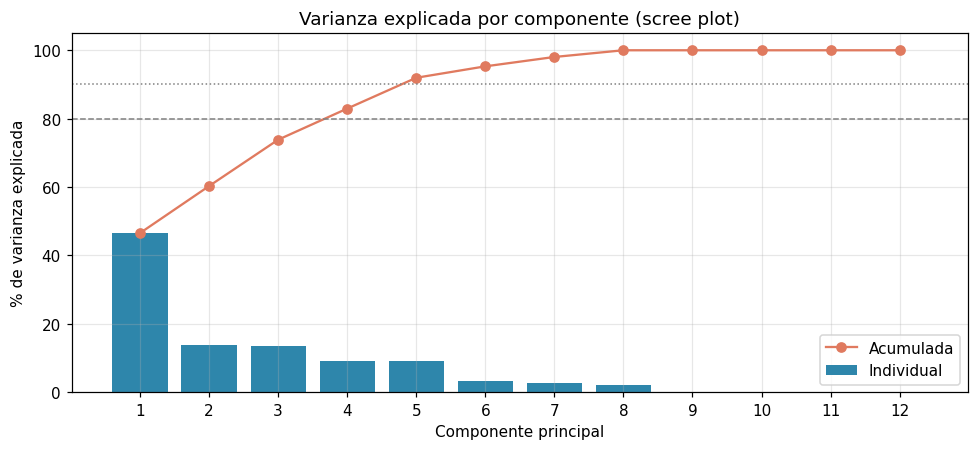

In [3]:
pca_full = PCA().fit(X)
evr = pca_full.explained_variance_ratio_
tabla_var = pd.DataFrame({"Componente": [f"PC{i+1}" for i in range(len(evr))],
                          "Varianza_%": (evr * 100).round(2), "Acumulada_%": (np.cumsum(evr) * 100).round(2)})
display(tabla_var)
print(f"PC1 + PC2 explican {np.cumsum(evr)[1]*100:.2f}% de la varianza")
print("Componentes para conservar >=80%:", np.argmax(np.cumsum(evr) >= 0.80) + 1,
      "| >=90%:", np.argmax(np.cumsum(evr) >= 0.90) + 1)
print("Rango efectivo de X:", np.linalg.matrix_rank(X - X.mean(0)), "(las variables one-hot son redundantes)")

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(1, len(evr) + 1)
ax.bar(x, evr * 100, color="#2E86AB", label="Individual")
ax.plot(x, np.cumsum(evr) * 100, "o-", color="#E07A5F", label="Acumulada")
ax.axhline(80, ls="--", c="gray", lw=1); ax.axhline(90, ls=":", c="gray", lw=1)
ax.set_xticks(x); ax.set_xlabel("Componente principal"); ax.set_ylabel("% de varianza explicada")
ax.set_title("Varianza explicada por componente (scree plot)"); ax.legend()
guardar("08_varianza_pca")

## 3. Interpretación de los componentes (cargas)

,PC1,PC2,PC3,PC4
num__Precio_arriendo,0.500,-0.016,-0.029,-0.035
num__Area_m2,0.493,0.031,0.003,0.003
num__Habitaciones,0.492,0.010,0.018,0.027
num__Banos,0.016,-0.649,0.760,-0.010
num__Antiguedad_anios,-0.022,0.758,0.647,-0.038
num__Estrato,0.511,0.034,0.016,0.017
cat__Localidad_Chapinero,-0.012,0.005,-0.009,-0.479
cat__Localidad_Suba,-0.015,0.023,0.021,0.517
cat__Localidad_Usaquén,0.027,-0.027,-0.012,-0.037
cat__Tipo_inmueble_ApartaEstudio,0.027,-0.027,-0.012,-0.037


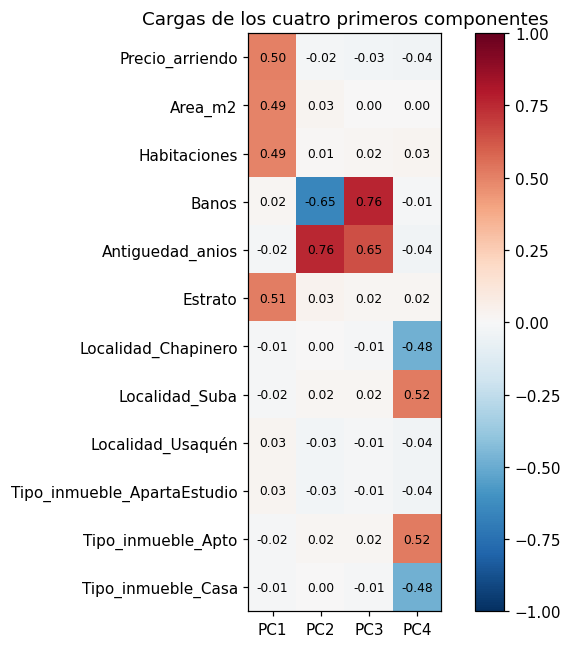

In [4]:
cargas = pd.DataFrame(pca_full.components_[:4].T, index=nombres, columns=["PC1", "PC2", "PC3", "PC4"])
display(cargas.round(3))
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(cargas.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(cargas.columns)
ax.set_yticks(range(len(nombres))); ax.set_yticklabels([n.split("__")[1] for n in nombres])
for i in range(len(nombres)):
    for j in range(4): ax.text(j, i, f"{cargas.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Cargas de los cuatro primeros componentes"); ax.grid(False)
guardar("09_cargas_pca")

- **PC1 (≈46,5 %) – "tamaño y valor del inmueble":** cargas casi iguales (~0,5) de precio, área, habitaciones y estrato.
- **PC2 (≈13,8 %) – "antigüedad vs. baños":** antigüedad positiva, baños negativa.
- Localidad y tipo de inmueble casi no pesan en PC1–PC2; su información se reparte en componentes posteriores.

## 4. Proyección en 2 componentes y visualización de los clusters

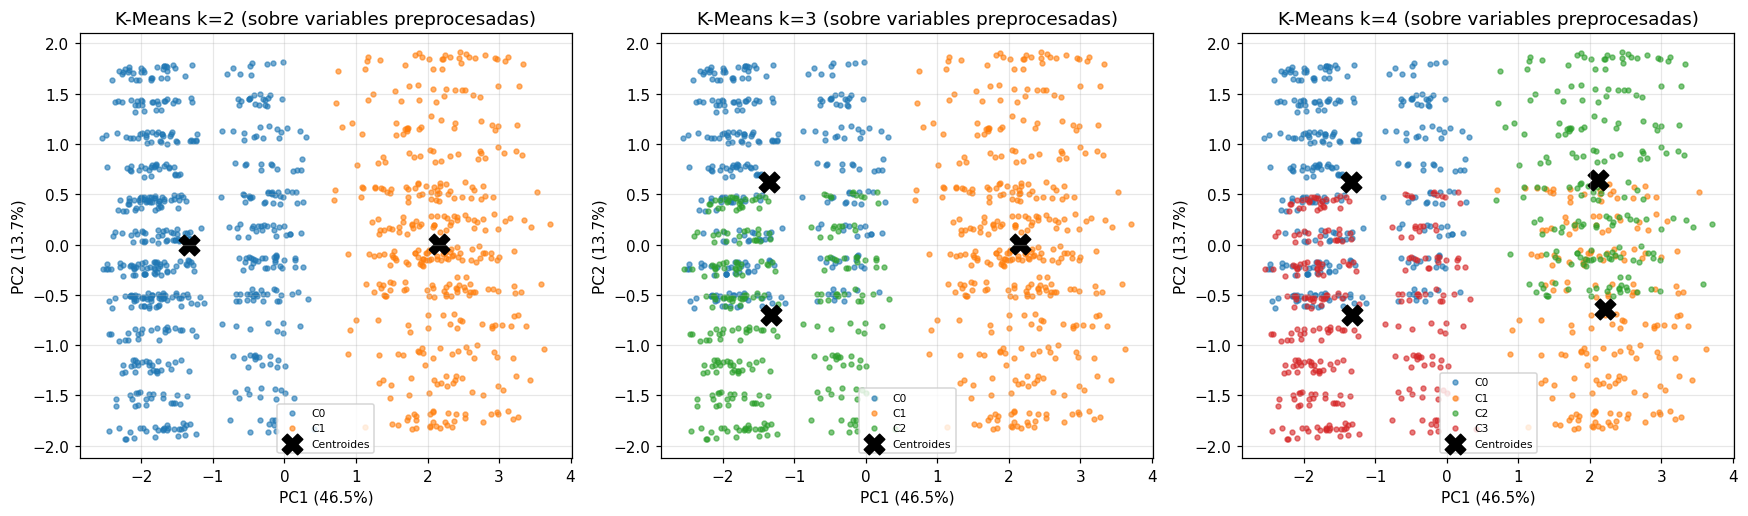

In [5]:
pca2 = PCA(n_components=2, random_state=42); Z = pca2.fit_transform(X)
modelos = {k: KMeans(n_clusters=k, random_state=42, n_init=10).fit(X) for k in (2, 3, 4)}
etiquetas = {k: m.labels_ for k, m in modelos.items()}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, k in zip(ax, (2, 3, 4)):
    lab = etiquetas[k]
    for c in range(k):
        a.scatter(Z[lab == c, 0], Z[lab == c, 1], s=10, alpha=0.6, label=f"C{c}")
    cz = pca2.transform(modelos[k].cluster_centers_); a.scatter(cz[:, 0], cz[:, 1], marker="X", s=180, c="black", label="Centroides")
    a.set_title(f"K-Means k={k} (sobre variables preprocesadas)"); a.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); a.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)"); a.legend(fontsize=7)
guardar("10_kmeans_en_plano_pca")

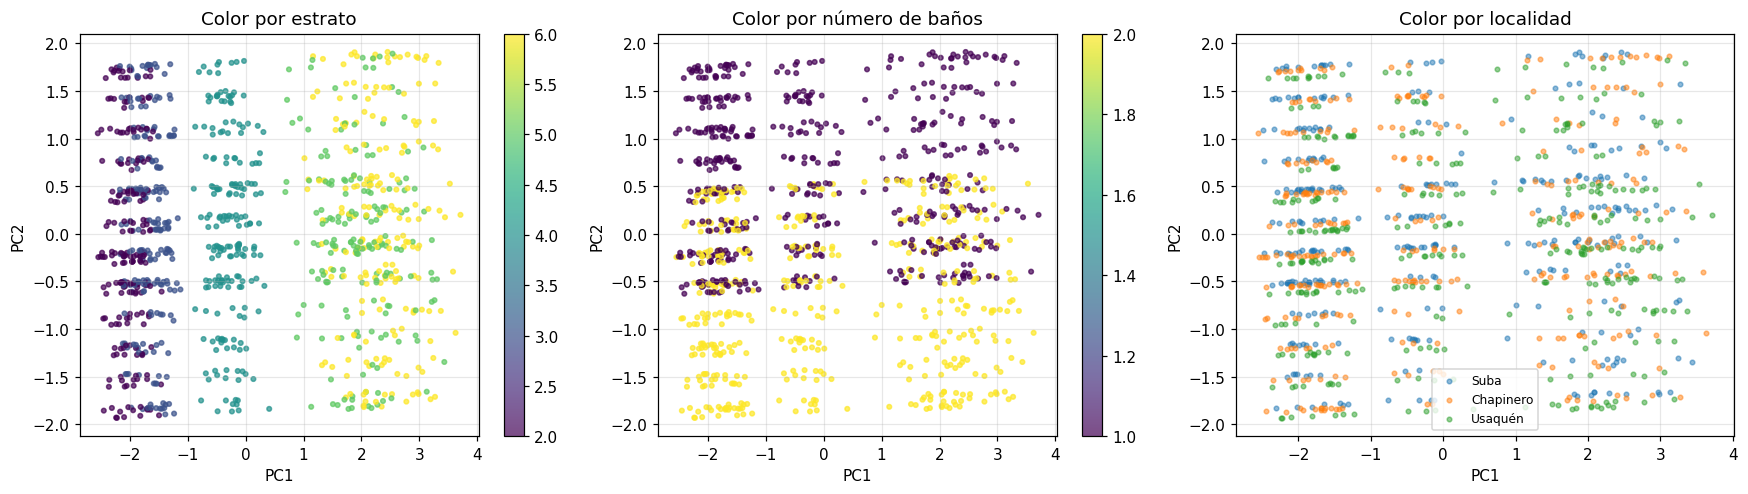

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (var, tit) in zip(ax, [("Estrato", "Color por estrato"), ("Banos", "Color por número de baños"), ("Localidad", "Color por localidad")]):
    if var == "Localidad":
        for loc in df.Localidad.unique():
            msk = (df.Localidad == loc).values; a.scatter(Z[msk, 0], Z[msk, 1], s=9, alpha=0.5, label=loc)
        a.legend(fontsize=8)
    else:
        sc = a.scatter(Z[:, 0], Z[:, 1], c=df[var], cmap="viridis", s=9, alpha=0.7); plt.colorbar(sc, ax=a)
    a.set_title(tit); a.set_xlabel("PC1"); a.set_ylabel("PC2")
guardar("11_pca_por_variable")

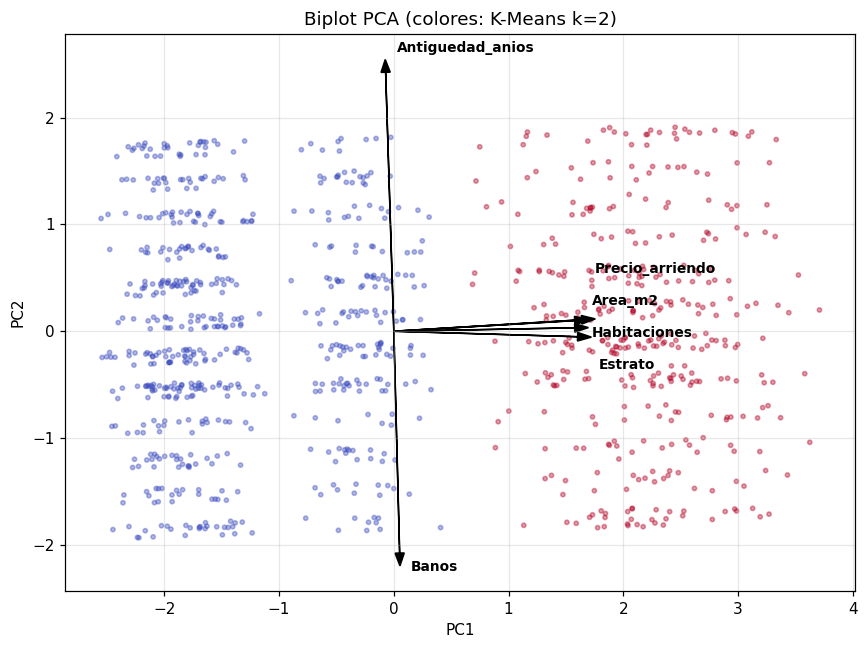

In [7]:
# Biplot: puntos coloreados por k=2 y vectores de carga de las variables numéricas
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=etiquetas[2], cmap="coolwarm", s=8, alpha=0.4)
esc = 3.2; desfase = 0
for i, n in enumerate(nombres):
    if n.startswith("num__"):
        x1, y1 = pca2.components_[0, i] * esc, pca2.components_[1, i] * esc
        ax.arrow(0, 0, x1, y1, color="black", head_width=0.08)
        if abs(y1) < 0.3:                      # vectores casi superpuestos sobre PC1
            ax.text(x1 + 0.15, 0.55 - desfase, n[5:], fontsize=9, fontweight="bold"); desfase += 0.3
        else:
            ax.text(x1 + 0.1, y1 * 1.08, n[5:], fontsize=9, fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Biplot PCA (colores: K-Means k=2)")
guardar("12_biplot")

## 5. ¿Cambian los grupos al aplicar K-Means sobre los componentes principales?

In [8]:
p90 = PCA(n_components=0.90, random_state=42); Z90 = p90.fit_transform(X)
filas = []
for k in (2, 3, 4):
    lx = etiquetas[k]
    lz2 = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(Z)
    lz90 = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(Z90)
    filas.append({"k": k,
                  "ARI(preproc. vs PCA-2)": adjusted_rand_score(lx, lz2),
                  f"ARI(preproc. vs PCA-{p90.n_components_})": adjusted_rand_score(lx, lz90),
                  "silueta preproc. (en X)": silhouette_score(X, lx),
                  "silueta PCA-2 (en Z)": silhouette_score(Z, lz2)})
comparacion = pd.DataFrame(filas).set_index("k"); display(comparacion.round(3))

,ARI(preproc. vs PCA-2),ARI(preproc. vs PCA-5),silueta preproc. (en X),silueta PCA-2 (en Z)
k,,,,
2,1.000,1.0,0.350,0.571
3,0.680,1.0,0.255,0.450
4,0.482,1.0,0.222,0.375


Perfil de K-Means k=3 entrenado sobre PC1–PC2:


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,n
c,,,,,,,
0,2011278.3,61.4,1.9,1.2,10.1,3.0,308
1,6300711.6,154.6,4.0,1.5,8.4,5.5,382
2,1957874.6,60.5,1.8,1.7,7.0,2.9,310


Perfil de K-Means k=3 entrenado sobre las variables preprocesadas:


,Precio_arriendo,Area_m2,Habitaciones,Banos,Antiguedad_anios,Estrato,n
c,,,,,,,
0,2000101.3,61.3,1.8,1.0,8.6,3.0,326
1,6300711.6,154.6,4.0,1.5,8.4,5.5,382
2,1967061.1,60.7,1.8,2.0,8.5,3.0,292


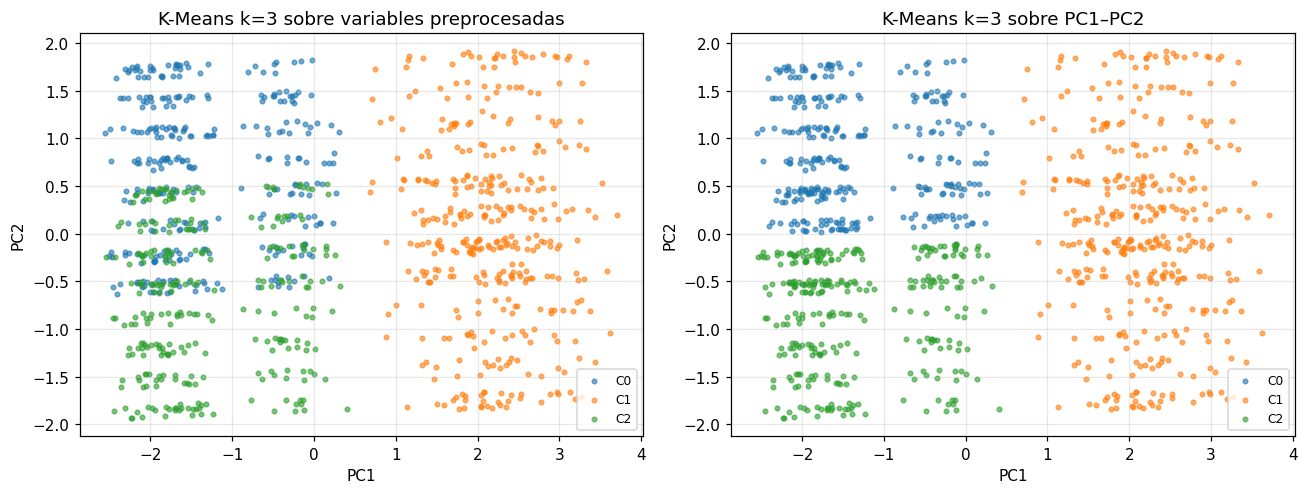

In [9]:
lz3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Z)
print("Perfil de K-Means k=3 entrenado sobre PC1–PC2:")
display(df.assign(c=lz3).groupby("c")[NUM].mean().round(1).assign(n=np.bincount(lz3)))
print("Perfil de K-Means k=3 entrenado sobre las variables preprocesadas:")
display(df.assign(c=etiquetas[3]).groupby("c")[NUM].mean().round(1).assign(n=np.bincount(etiquetas[3])))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, lab, t in [(ax[0], etiquetas[3], "K-Means k=3 sobre variables preprocesadas"), (ax[1], lz3, "K-Means k=3 sobre PC1–PC2")]:
    for c in range(3): a.scatter(Z[lab == c, 0], Z[lab == c, 1], s=9, alpha=0.6, label=f"C{c}")
    a.set_title(t); a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.legend(fontsize=8)
guardar("13_kmeans_preproc_vs_pca")

Con k = 2 la partición es **idéntica** (ARI = 1): la separación ocurre a lo largo de PC1. Con k = 3 y 4 los grupos cambian: sobre las variables preprocesadas el criterio extra es el número de baños; sobre PC1–PC2 el criterio extra pasa a ser la antigüedad (eje PC2), porque la proyección mezcla baños y antigüedad en un mismo eje.

## 6. Comparación con SVD truncado

In [10]:
svd = TruncatedSVD(n_components=2, random_state=42).fit(X)
print("Varianza explicada SVD (2 comp.):", (svd.explained_variance_ratio_ * 100).round(2), "%")
print("Varianza explicada PCA (2 comp.):", (pca2.explained_variance_ratio_ * 100).round(2), "%")
Zs = svd.transform(X)
print("Correlación |PC1 vs SVD1|:", abs(np.corrcoef(Z[:, 0], Zs[:, 0])[0, 1]).round(4),
      "| |PC2 vs SVD2|:", abs(np.corrcoef(Z[:, 1], Zs[:, 1])[0, 1]).round(4))

Varianza explicada SVD (2 comp.): [46.54 13.75] %
Varianza explicada PCA (2 comp.): [46.54 13.75] %
Correlación |PC1 vs SVD1|: 1.0 | |PC2 vs SVD2|: 1.0


PCA es una SVD aplicada a los datos centrados. Como las variables numéricas ya están estandarizadas, SVD truncado produce prácticamente los mismos ejes; su ventaja real aparece en matrices dispersas muy grandes (texto, sistemas de recomendación), donde no conviene centrar los datos.

## 7. Enfoque propuesto visto en el plano PCA

Varianza explicada con variables núcleo (PC1, PC2): [85.1  6.1]


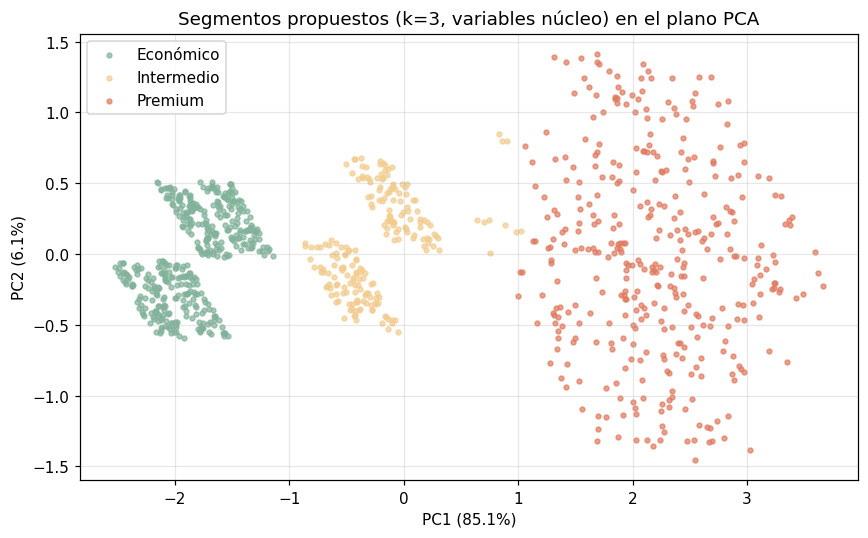

In [11]:
NUCLEO = ["Precio_arriendo", "Area_m2", "Habitaciones", "Estrato"]
Xn = StandardScaler().fit_transform(df[NUCLEO])
ln = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(Xn)
orden = pd.Series(df.Precio_arriendo.values).groupby(ln).mean().sort_values().index
nom = dict(zip(orden, ["Económico", "Intermedio", "Premium"])); seg = pd.Series(ln).map(nom)
pn = PCA(2).fit(Xn); Zn = pn.transform(Xn)
print("Varianza explicada con variables núcleo (PC1, PC2):", (pn.explained_variance_ratio_ * 100).round(1))
colores = {"Económico": "#81B29A", "Intermedio": "#F2CC8F", "Premium": "#E07A5F"}
fig, ax = plt.subplots(figsize=(8, 5))
for s, c in colores.items():
    m = (seg == s).values; ax.scatter(Zn[m, 0], Zn[m, 1], s=10, alpha=0.7, color=c, label=s)
ax.set_xlabel(f"PC1 ({pn.explained_variance_ratio_[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({pn.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Segmentos propuestos (k=3, variables núcleo) en el plano PCA"); ax.legend()
guardar("14_segmentos_propuestos_pca")

## 8. Conclusiones
- El espacio preprocesado tiene 12 dimensiones, pero su rango efectivo es 8 (la codificación one-hot es redundante). Dos componentes conservan ≈60 % de la varianza y cinco superan el 90 %.
- PC1 resume el "tamaño/valor" del inmueble y es el eje sobre el que se separan los grupos naturales; PC2 recoge antigüedad y baños.
- En el plano PC1–PC2 los dos grupos de k = 2 se distinguen claramente; los grupos adicionales de k = 3 y 4 (por baños) se superponen. El plano revela además tres franjas a lo largo de PC1 (estratos 2–3, 4 y 5–6): una pista visual del segmento intermedio que K-Means con todas las variables no captura.
- PCA es muy útil para visualizar y explicar; para segmentar, conviene seleccionar las variables comercialmente relevantes antes de agrupar.